# Mumbai Cab Fare - Exploratory Data Analysis

> **Data note:** the dataset analysed here is **simulated** by `train_mumbai_model.py` (pricing rules in
> `platform_fares.json` + noise). Patterns below describe the *simulation's rules*, not real Mumbai ridership,
> so they should not be presented as real-world findings.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)
df = pd.read_csv("mumbai_cab_fare_train.csv")
print("Rows, columns:", df.shape)
print(df.columns.tolist())

Rows, columns: (7200, 17)
['pickup_latitude', 'pickup_longitude', 'dropoff_latitude', 'dropoff_longitude', 'route_distance_km', 'route_duration_min', 'pickup_hour', 'weather_flag', 'traffic_level', 'ola_fare', 'uber_fare', 'rapido_fare', 'kaali_peeli_fare', 'fare_amount', 'route_group', 'is_peak', 'is_night']


## 1. Data quality

In [2]:
display(df.head())
display(df.describe().T.round(2))
print("Missing values:", int(df.isnull().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()))

Missing values: 0 | Duplicate rows: 0


,pickup_latitude,pickup_longitude,dropoff_latitude,dropoff_longitude,route_distance_km,route_duration_min,pickup_hour,weather_flag,traffic_level,ola_fare,uber_fare,rapido_fare,kaali_peeli_fare,fare_amount,route_group,is_peak,is_night
0,18.937555,72.849644,19.134295,72.891767,32.20,84.8,17,0,Heavy,934.63,1114.95,578.13,602.07,807.45,379_1457>383_1458,1,0
1,19.139310,72.905737,19.061783,72.812053,18.30,42.7,5,1,Moderate,518.60,622.22,323.08,337.03,450.24,383_1458>381_1456,0,0
2,19.125069,72.889752,18.929972,72.830722,30.99,60.6,9,0,Moderate,893.65,1026.25,518.60,563.70,750.55,383_1458>379_1457,1,0
3,19.054776,72.875493,19.090407,73.006611,17.83,45.3,10,1,Heavy,658.48,778.99,378.96,334.98,537.85,381_1458>382_1460,1,0
4,19.198594,72.989577,18.950394,72.831607,44.58,52.0,12,0,Low,972.76,985.00,624.57,789.90,843.06,384_1460>379_1457,0,0


,count,mean,std,min,25%,50%,75%,max
pickup_latitude,7200.0,19.06,0.08,18.90,19.02,19.07,19.11,19.26
pickup_longitude,7200.0,72.88,0.06,72.78,72.84,72.86,72.91,73.04
dropoff_latitude,7200.0,19.06,0.33,18.39,18.94,19.07,19.12,20.03
dropoff_longitude,7200.0,73.03,0.31,72.78,72.84,72.88,73.01,73.88
route_distance_km,7200.0,44.88,52.00,0.60,11.68,23.08,58.17,227.98
route_duration_min,7200.0,73.52,67.86,1.00,29.40,53.80,88.60,459.80
pickup_hour,7200.0,11.51,6.86,0.00,6.00,12.00,17.00,23.00
weather_flag,7200.0,0.30,0.56,0.00,0.00,0.00,0.00,2.00
ola_fare,7200.0,1147.40,1254.60,48.61,350.20,645.90,1401.30,7460.21
uber_fare,7200.0,1281.68,1409.10,55.13,389.40,720.62,1562.84,8585.57


No missing values or duplicates (expected for generated data). Distance is **bimodal**: 32% of trips
are intentionally long (>40 km, Mumbai to outer-MMR towns) so the model also sees highway-length trips.

## 2. Distributions

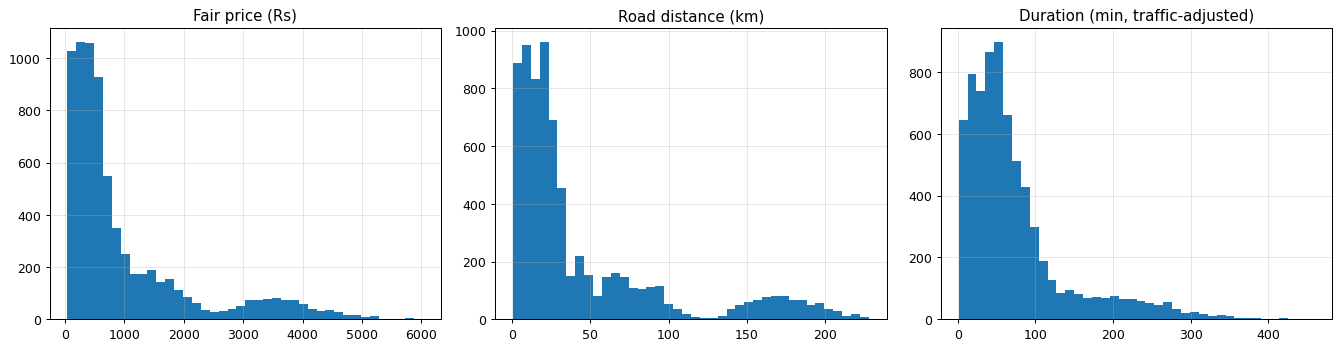

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df["fare_amount"], bins=40);          axes[0].set_title("Fair price (Rs)")
axes[1].hist(df["route_distance_km"], bins=40);    axes[1].set_title("Road distance (km)")
axes[2].hist(df["route_duration_min"], bins=40);   axes[2].set_title("Duration (min, traffic-adjusted)")
for a in axes: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 3. What drives the fare?

,fare_amount,route_distance_km,route_duration_min,pickup_hour,is_peak,is_night,weather_flag
fare_amount,1.000,0.986,0.955,0.016,0.058,-0.001,0.055
route_distance_km,0.986,1.000,0.936,0.013,-0.012,-0.013,-0.019
route_duration_min,0.955,0.936,1.000,0.067,0.111,-0.061,0.031
pickup_hour,0.016,0.013,0.067,1.000,0.372,-0.702,0.015
is_peak,0.058,-0.012,0.111,0.372,1.000,-0.394,0.006
is_night,-0.001,-0.013,-0.061,-0.702,-0.394,1.000,-0.001
weather_flag,0.055,-0.019,0.031,0.015,0.006,-0.001,1.000


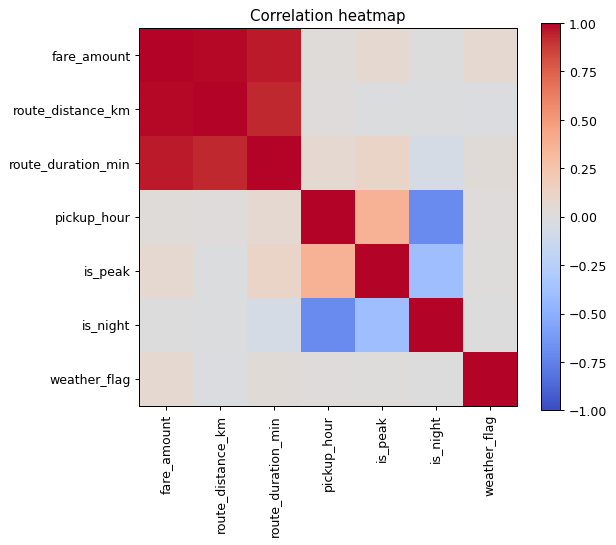

In [4]:
cols = ["fare_amount", "route_distance_km", "route_duration_min", "pickup_hour", "is_peak", "is_night", "weather_flag"]
corr = df[cols].corr()
display(corr.round(3))
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=90)
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
plt.colorbar(im); ax.set_title("Correlation heatmap"); plt.tight_layout(); plt.show()

Distance is by far the strongest driver (correlation with fare = 0.99). Hour of day alone is weakly correlated: its effect works through the peak/night flags.

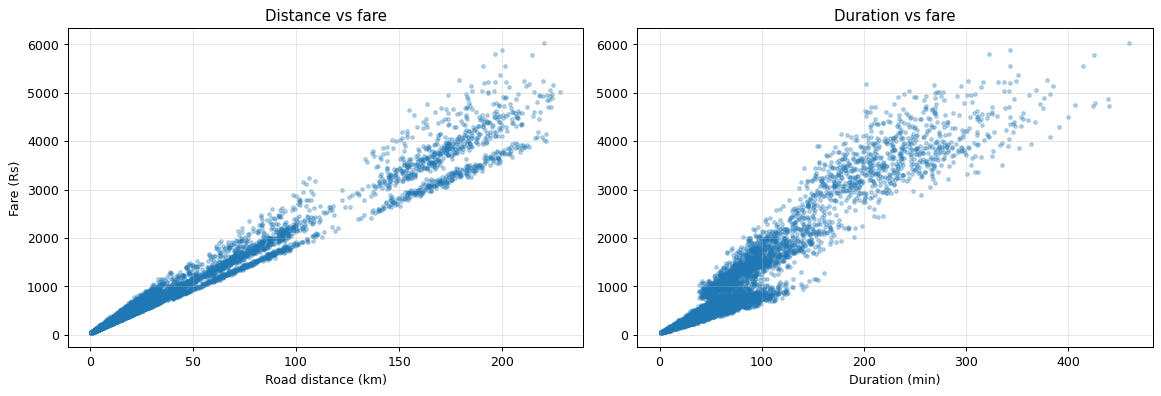

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(df["route_distance_km"], df["fare_amount"], alpha=0.3, s=8)
axes[0].set_xlabel("Road distance (km)"); axes[0].set_ylabel("Fare (Rs)"); axes[0].set_title("Distance vs fare")
axes[1].scatter(df["route_duration_min"], df["fare_amount"], alpha=0.3, s=8)
axes[1].set_xlabel("Duration (min)"); axes[1].set_title("Duration vs fare")
for a in axes: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4. Time, weather and traffic effects (fare per km, so trip length does not hide the effect)

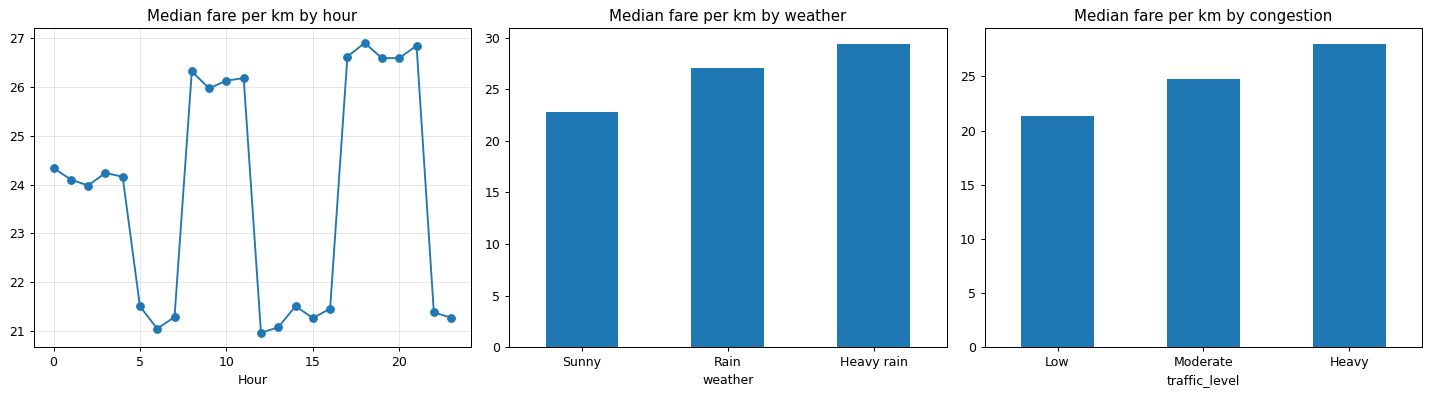

In [6]:
df["fare_per_km"] = df["fare_amount"] / df["route_distance_km"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
df.groupby("pickup_hour")["fare_per_km"].median().plot(ax=axes[0], marker="o")
axes[0].set_title("Median fare per km by hour"); axes[0].set_xlabel("Hour"); axes[0].grid(alpha=0.3)
df.assign(weather=df["weather_flag"].map({0: "Sunny", 1: "Rain", 2: "Heavy rain"})).groupby("weather")["fare_per_km"].median() \
  .reindex(["Sunny", "Rain", "Heavy rain"]).plot.bar(ax=axes[1], rot=0)
axes[1].set_title("Median fare per km by weather")
df.groupby("traffic_level")["fare_per_km"].median().reindex(["Low", "Moderate", "Heavy"]).plot.bar(ax=axes[2], rot=0)
axes[2].set_title("Median fare per km by congestion")
plt.tight_layout(); plt.show()

Rain and rush hours lift the fare per km (peak-hour trips cost about 1.25x per km vs normal hours in this data); mean fare rises from Rs 972 (sunny) to Rs 1208 (heavy rain) partly because heavier rain also brings more congestion and longer durations.

## 5. Platform comparison (simulated)

,mean,50%,max
ola_fare,1147.4,645.9,7460.2
uber_fare,1281.7,720.6,8585.6
rapido_fare,708.2,396.2,4094.5
kaali_peeli_fare,879.8,452.4,5357.9
fare_amount,1004.3,556.9,6032.6


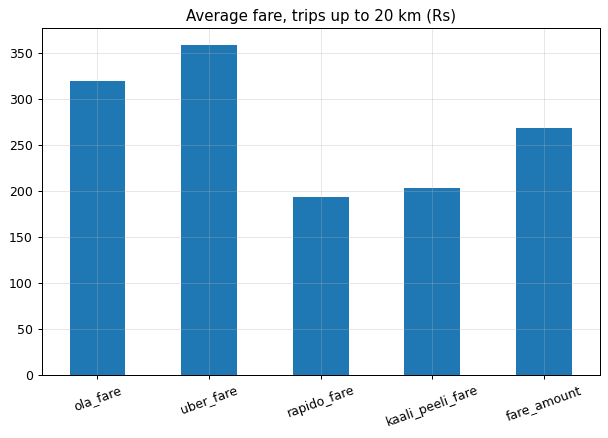

In [7]:
platforms = ["ola_fare", "uber_fare", "rapido_fare", "kaali_peeli_fare", "fare_amount"]
display(df[platforms].describe().T[["mean", "50%", "max"]].round(1))
df[df["route_distance_km"] <= 20][platforms].mean().plot.bar(rot=20, title="Average fare, trips up to 20 km (Rs)")
plt.grid(alpha=0.3); plt.show()

## 6. Outliers
Long trips are *by design* in this dataset, so IQR 'outliers' are mostly valid long-distance fares, not errors. Do not delete them.

In [8]:
q1, q3 = df["fare_amount"].quantile([0.25, 0.75]); iqr = q3 - q1
outliers = df[(df["fare_amount"] < q1 - 1.5 * iqr) | (df["fare_amount"] > q3 + 1.5 * iqr)]
print(f"IQR outliers: {len(outliers)} ({len(outliers) / len(df):.1%}); share of them that are > 40 km trips: "
      f"{(outliers['route_distance_km'] > 40).mean():.0%}")

IQR outliers: 806 (11.2%); share of them that are > 40 km trips: 100%


## 7. Takeaways for modelling
- Distance and duration dominate; peak, night and weather act as multipliers, so the model predicts a **fare / baseline ratio**.
- Coordinates, passenger count and weekday were removed because the pricing rules do not use them.
- Because the data is simulated, validate against real fare receipts before claiming real-world accuracy.